# Milestone 2: Data Quality dan Profiling

Lanjutkan dari hasil `01_data_profiling.ipynb`. Notebook ini menerapkan profiling DuckDB `SUMMARIZE` dan transformasi Polars untuk menangani missing values, outlier, duplikat, serta validasi data dasar. Nama kolom dan aturan validasi sudah disesuaikan dengan dataset banjir Sulawesi Selatan.


In [45]:
import time
from pathlib import Path

import duckdb
import polars as pl


def find_project_root(start=None):
    """Naik ke folder induk sampai menemukan folder data/ dan notebooks/."""
    start = (start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / 'data').is_dir() and (folder / 'notebooks').is_dir():
            return folder
    return start


PROJECT_ROOT = find_project_root()
RAW_CSV = PROJECT_ROOT / "data" / "raw" / "modis_flood_features_paling cleaning.csv"
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "flood_features.parquet"
OUTPUT_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dataset_bersih.parquet'
TABLES_DIR = PROJECT_ROOT / 'output' / 'tables'
FIGURES_DIR = PROJECT_ROOT / 'output' / 'figures'
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if DATA_PATH.exists():
    df = pl.read_parquet(DATA_PATH)
elif RAW_CSV.exists():
    print('Parquet dari notebook 01 belum ada, membaca CSV mentah.')
    df = pl.read_csv(RAW_CSV, try_parse_dates=True)
else:
    raise FileNotFoundError(
        f'Dataset tidak ditemukan: {DATA_PATH}. '
        'Pastikan Milestone 1 sudah dijalankan dan data ada di data/raw/.'
    )

print(f'Ukuran awal: {df.shape[0]:,} baris x {df.shape[1]} kolom')
df.head()

Ukuran awal: 1,025,801 baris x 16 kolom


date,lon,lat,flooded,jrc_perm_water,precip_1d,precip_3d,NDVI,NDWI,landcover,elevation,slope,aspect,upstream_area,TWI,target
date,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
2003-12-10,120.478677,-6.495942,1.0,1.0,9.645125,28.935376,6190.93062,-0.051446,17.0,0.0,0.116685,270.0,0.03199,1.042098,0
2003-12-10,120.480923,-6.495942,1.0,1.0,9.645125,28.935376,6190.93062,-0.051446,17.0,1.0,0.839713,236.480074,0.03199,1.042098,0
2003-12-10,120.478677,-6.493697,0.0,1.0,9.645125,28.935376,6190.93062,0.028399,17.0,0.0,0.46673,270.0,0.03199,1.042098,0
2003-12-10,120.480923,-6.493697,1.0,0.0,9.645125,28.935376,6190.93062,0.028399,17.0,4.0,0.939179,240.413746,0.021235,0.258796,1
2003-12-10,120.478677,-6.491451,0.0,1.0,9.645125,28.935376,6190.93062,-0.002506,17.0,0.0,0.583403,270.0,0.03199,1.042098,0


## 1. Profiling dengan DuckDB `SUMMARIZE`

Ringkasan statistik seluruh kolom (tipe data, null%, min/max, distinct count) dalam satu perintah. Hasilnya disimpan sebagai bukti kondisi data **sebelum** cleaning.

In [46]:
connection = duckdb.connect()
connection.register('dataset', df)

profil = connection.execute('SUMMARIZE SELECT * FROM dataset').pl()
profil.write_csv(str(TABLES_DIR / 'summarize_before.csv'))
profil

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
str,str,str,str,i64,str,str,str,str,str,i64,"decimal[9,2]"
"""date""","""DATE""","""2003-12-10""","""2015-02-05""",7,"""2008-04-07 17:08:34.285714""",null,"""2004-05-07""","""2007-06-16""","""2013-01-03""",1025801,0.00
"""lon""","""DOUBLE""","""119.353537330435""","""121.790217538609""",978,"""120.17780767018606""","""0.5295104965429553""","""119.79084956494766""","""120.15347232799515""","""120.35724668180404""",1025801,0.00
"""lat""","""DOUBLE""","""-6.49594239828929""","""-1.89432235538704""",2049,"""-3.9619865334552293""","""1.0182037099318215""","""-4.769196551644429""","""-4.001456466099041""","""-2.856454635636944""",1025801,0.00
"""flooded""","""DOUBLE""","""0.0""","""1.0""",2,"""0.11205779678514644""","""0.3154377021902979""","""0.0""","""0.0""","""0.0""",1025801,0.00
"""jrc_perm_water""","""DOUBLE""","""0.0""","""1.0""",2,"""0.0932217847321264""","""0.2907431271567856""","""0.0""","""0.0""","""0.0""",1025801,0.00
…,…,…,…,…,…,…,…,…,…,…,…
"""slope""","""DOUBLE""","""0.0""","""26.7202548980713""",76687,"""1.062714596026718""","""1.597632463039042""","""0.25816024596836684""","""0.5045363633142184""","""1.1942411285759675""",1025801,0.00
"""aspect""","""DOUBLE""","""0.0""","""359.348113230288""",94169,"""155.00511701328097""","""106.33727544886943""","""63.24185646540049""","""152.63126100082152""","""245.90538516282294""",1025801,0.00
"""upstream_area""","""DOUBLE""","""0.008497217670083""","""5128.52783203125""",154214,"""16.33299110814641""","""149.26224728267428""","""0.022313666964333866""","""0.0885463452549737""","""0.5948868442535484""",1025801,0.00


In [48]:

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots


def tampilkan(fig, nama):
    """Tampilkan grafik interaktif dan simpan sebagai HTML di output/figures/."""
    fig.update_layout(template='plotly_white', margin=dict(t=70, l=60, r=20, b=60))
    fig.show()
    fig.write_html(str(FIGURES_DIR / f'{nama}.html'), include_plotlyjs='cdn')


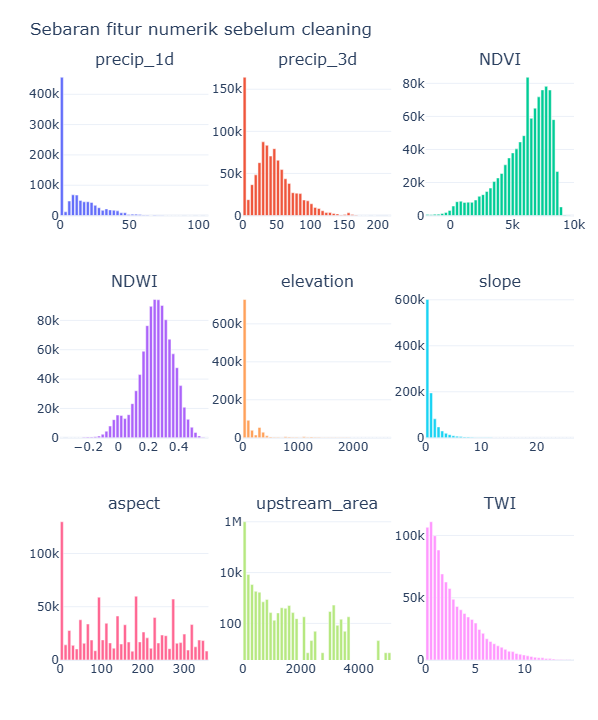

In [50]:

KOLOM_HIST = ['precip_1d', 'precip_3d', 'NDVI', 'NDWI', 'elevation', 'slope', 'aspect', 'upstream_area', 'TWI']
JUMLAH_BIN = 40

fig0 = make_subplots(rows=3, cols=3, subplot_titles=KOLOM_HIST, vertical_spacing=0.13)
for i, k in enumerate(KOLOM_HIST):
    nilai_min, nilai_max = df[k].min(), df[k].max()
    lebar = (nilai_max - nilai_min) / JUMLAH_BIN
    ringkas = (
        df.select(((pl.col(k) - nilai_min) / lebar).floor().clip(0, JUMLAH_BIN - 1).alias('bin'))
        .group_by('bin').agg(pl.len().alias('n')).sort('bin')
    )
    x = [nilai_min + (b + 0.5) * lebar for b in ringkas['bin'].to_list()]
    fig0.add_bar(x=x, y=ringkas['n'].to_list(), row=i // 3 + 1, col=i % 3 + 1, showlegend=False)

fig0.update_yaxes(type='log', row=3, col=2)   # upstream_area: sumbu Y logaritmik
fig0.update_layout(title='Sebaran fitur numerik sebelum cleaning ', height=720)
tampilkan(fig0, 'qc_00_sebaran_fitur_awal')


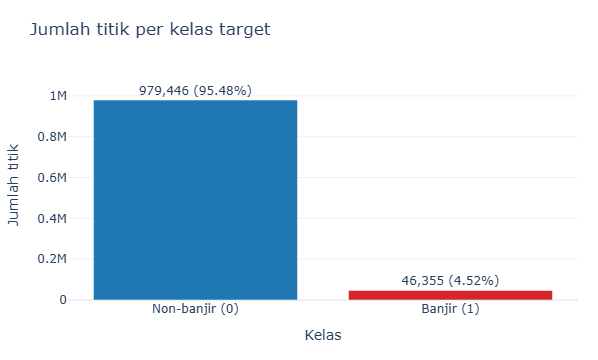

In [51]:

kelas = df.group_by('target').agg(pl.len().alias('n')).sort('target')
total = kelas['n'].sum()
label_kelas = {0: 'Non-banjir (0)', 1: 'Banjir (1)'}

fig_kelas = go.Figure(go.Bar(
    x=[label_kelas[t] for t in kelas['target'].to_list()],
    y=kelas['n'].to_list(),
    text=[f'{n:,} ({n / total:.2%})' for n in kelas['n'].to_list()],
    textposition='outside',
    marker_color=['#1f77b4', '#d62728'],
))
fig_kelas.update_layout(title='Jumlah titik per kelas target', yaxis_title='Jumlah titik', xaxis_title='Kelas')
tampilkan(fig_kelas, 'qc_01_keseimbangan_kelas')


## 2. Deteksi Missing Values

Cek jumlah dan persentase null per kolom sebelum penanganan missing value. Tabel hanya menampilkan kolom yang memiliki null, sehingga **tabel kosong berarti tidak ada null**.

In [52]:
jumlah_baris = len(df)
null_summary = (
    df.null_count()
    .transpose(include_header=True, header_name='kolom', column_names=['jumlah_null'])
    .with_columns(
        (pl.col('jumlah_null') / jumlah_baris * 100).round(2).alias('persen_null')
    )
    .filter(pl.col('jumlah_null') > 0)
    .sort('jumlah_null', descending=True)
)
print(f'Kolom dengan null: {null_summary.height}')
null_summary

Kolom dengan null: 0


kolom,jumlah_null,persen_null
str,u32,f64


`null_count()` hanya menghitung null. Kolom desimal juga bisa berisi `NaN` atau nilai tak berhingga (`inf`) yang tidak dihitung sebagai null, sehingga perlu diperiksa terpisah.

In [53]:
KOLOM_FLOAT = [k for k, t in df.schema.items() if t in (pl.Float32, pl.Float64)]

jumlah_nan = sum(df.select([pl.col(k).is_nan().sum() for k in KOLOM_FLOAT]).row(0))
jumlah_inf = sum(df.select([pl.col(k).is_infinite().sum() for k in KOLOM_FLOAT]).row(0))
print(f'Total NaN: {jumlah_nan:,}')
print(f'Total inf: {jumlah_inf:,}')

Total NaN: 0
Total inf: 0


## 3. Penanganan Missing Values

Strategi ditetapkan per jenis kolom (bukan satu aturan untuk semua):

| Jenis kolom | Kolom | Strategi |
|---|---|---|
| Kunci analisis | `date`, `lon`, `lat`, `target` | Baris dibuang bila null, karena tanpa waktu, lokasi, atau label baris tidak dapat dianalisis |
| Numerik | `precip_1d`, `precip_3d`, `NDVI`, `NDWI`, `elevation`, `slope`, `aspect`, `upstream_area`, `TWI` | Isi dengan **median** (tahan terhadap outlier) |
| Kategorik | `landcover` | Isi dengan **modus** (kelas yang paling sering muncul) |

Nilai `NaN` diubah dulu menjadi `null` agar diperlakukan seragam. Pada dataset ini tidak ada missing value, sehingga langkah ini tidak mengubah data, tetapi tetap dijalankan agar pipeline dapat dipakai ulang pada data lain.

In [54]:
KOLOM_KUNCI_ANALISIS = ['date', 'lon', 'lat', 'target']
KOLOM_NUMERIK_FITUR = ['precip_1d', 'precip_3d', 'NDVI', 'NDWI',
                       'elevation', 'slope', 'aspect', 'upstream_area', 'TWI']
KOLOM_KATEGORIK = ['landcover']

df_missing_handled = (
    df
    .with_columns([pl.col(k).fill_nan(None) for k in KOLOM_FLOAT])    # NaN -> null
    .drop_nulls(KOLOM_KUNCI_ANALISIS)                                  # kunci analisis tidak boleh null
    .with_columns(
        [pl.col(k).fill_null(pl.col(k).median()) for k in KOLOM_NUMERIK_FITUR]
        + [pl.col(k).fill_null(pl.col(k).mode().first()) for k in KOLOM_KATEGORIK]
    )
)

print(f'Null sebelum: {df.null_count().sum_horizontal().sum():,}')
print(f'Null sesudah: {df_missing_handled.null_count().sum_horizontal().sum():,}')
print(f'Baris sebelum: {len(df):,} | sesudah: {len(df_missing_handled):,}')

Null sebelum: 0
Null sesudah: 0
Baris sebelum: 1,025,801 | sesudah: 1,025,801


## 4. Deteksi dan Penanganan Outlier

Metode IQR dipakai sebagai titik awal (batas = Q1 - 1,5×IQR dan Q3 + 1,5×IQR), lalu dikombinasikan dengan batas fisik/domain. 
Kolom dipisah menurut sifatnya:

- **Variabel dinamis** (hujan, NDVI, NDWI, TWI): nilai ekstrem bisa berupa kejadian nyata atau galat sensor.
- **Variabel topografi statis** (`elevation`, `slope`, `upstream_area`): distribusinya miring ke kanan secara alami (banyak dataran rendah, sedikit pegunungan, akumulasi aliran sungai sangat besar di titik tertentu), sehingga IQR akan menandai banyak titik yang sebenarnya valid.

In [55]:
KOLOM_DINAMIS = ['precip_1d', 'precip_3d', 'NDVI', 'NDWI', 'TWI']
KOLOM_STATIS = ['elevation', 'slope', 'upstream_area']
KOLOM_NUMERIK = KOLOM_DINAMIS + KOLOM_STATIS

batas = {}
for kolom in KOLOM_NUMERIK:
    q1 = df_missing_handled[kolom].quantile(0.25)
    q3 = df_missing_handled[kolom].quantile(0.75)
    iqr = q3 - q1
    batas[kolom] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)

baris_tabel = []
for kolom in KOLOM_NUMERIK:
    batas_bawah, batas_atas = batas[kolom]
    n_outlier = df_missing_handled.filter(
        (pl.col(kolom) < batas_bawah) | (pl.col(kolom) > batas_atas)
    ).height
    baris_tabel.append({
        'kolom': kolom,
        'jenis': 'dinamis' if kolom in KOLOM_DINAMIS else 'statis',
        'batas_bawah': round(batas_bawah, 3),
        'batas_atas': round(batas_atas, 3),
        'n_outlier': n_outlier,
        'persen': round(n_outlier / len(df_missing_handled) * 100, 2),
        'median': round(df_missing_handled[kolom].median(), 3),
        'p99.9': round(df_missing_handled[kolom].quantile(0.999), 3),
        'max': round(df_missing_handled[kolom].max(), 3),
    })

tabel_outlier = pl.DataFrame(baris_tabel)
tabel_outlier.write_csv(str(TABLES_DIR / 'outlier_iqr.csv'))
tabel_outlier

kolom,jenis,batas_bawah,batas_atas,n_outlier,persen,median,p99.9,max
str,str,f64,f64,i64,f64,f64,f64,f64
"""precip_1d""","""dinamis""",-30.158,50.263,19382,1.89,7.932,73.553,107.288
"""precip_3d""","""dinamis""",-38.302,119.408,20487,2.0,39.327,164.5,220.219
"""NDVI""","""dinamis""",951.25,11513.25,30024,2.93,6417.0,9011.5,10000.0
"""NDWI""","""dinamis""",-0.032,0.542,23395,2.28,0.255,0.532,0.598
"""TWI""","""dinamis""",-3.928,9.037,29778,2.9,2.119,13.31,14.997
"""elevation""","""statis""",-107.5,208.5,164024,15.99,25.0,2049.0,2694.0
"""slope""","""statis""",-1.133,2.58,104202,10.16,0.493,14.911,26.72
"""upstream_area""","""statis""",-0.825,1.438,182161,17.76,0.088,3076.697,5128.528


#### Grafik: persentase outlier IQR per kolom

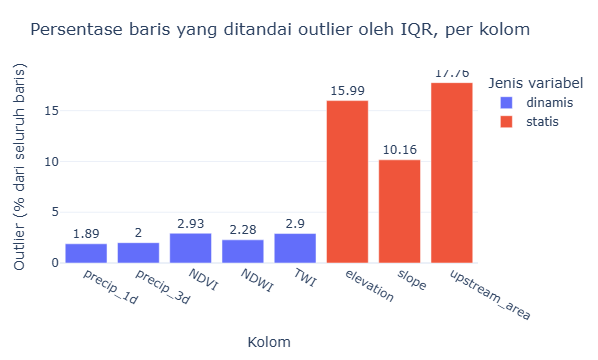

In [57]:

fig1 = px.bar(
    tabel_outlier.to_dict(as_series=False),
    x='kolom', y='persen', color='jenis', text='persen',
    title='Persentase baris yang ditandai outlier oleh IQR, per kolom',
    labels={'kolom': 'Kolom', 'persen': 'Outlier (% dari seluruh baris)', 'jenis': 'Jenis variabel'},
)
fig1.update_traces(textposition='outside')
tampilkan(fig1, 'qc_02_outlier_per_kolom')


### outlier 
Membandingkan proporsi outlier pada titik banjir (`target = 1`) dan non-banjir (`target = 0`). Jika outlier jauh lebih sering muncul pada titik banjir, nilai ekstrem itu kemungkinan membawa informasi, bukan galat.

In [56]:
tanda_outlier = [
    ((pl.col(k) < batas[k][0]) | (pl.col(k) > batas[k][1])).alias(k) for k in KOLOM_DINAMIS
]
persen_outlier_per_label = (
    df_missing_handled.select(['target'] + tanda_outlier)
    .group_by('target')
    .agg([pl.col(k).mean().round(4) for k in KOLOM_DINAMIS] + [pl.len().alias('n')])
    .sort('target')
)
persen_outlier_per_label

target,precip_1d,precip_3d,NDVI,NDWI,TWI,n
i64,f64,f64,f64,f64,f64,u32
0,0.019,0.0209,0.0254,0.0214,0.0285,979446
1,0.0177,0.0,0.1107,0.0528,0.0392,46355


#### Grafik: outlier pada titik banjir vs non-banjir

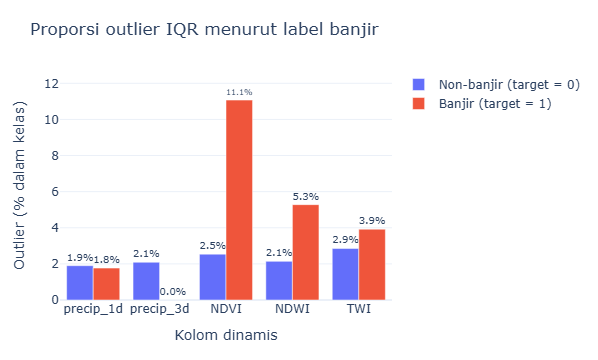

In [58]:

fig2 = go.Figure()
for nilai, nama in [(0, 'Non-banjir (target = 0)'), (1, 'Banjir (target = 1)')]:
    baris = persen_outlier_per_label.filter(pl.col('target') == nilai)
    persen = [baris[k][0] * 100 for k in KOLOM_DINAMIS]
    fig2.add_bar(x=KOLOM_DINAMIS, y=persen, name=nama,
                 text=[f'{p:.1f}%' for p in persen], textposition='outside')
fig2.update_layout(
    title='Proporsi outlier IQR menurut label banjir',
    xaxis_title='Kolom dinamis', yaxis_title='Outlier (% dalam kelas)', barmode='group',
)
tampilkan(fig2, 'qc_03_outlier_per_label')


#### Grafik: sebaran NDVI menurut label banjir

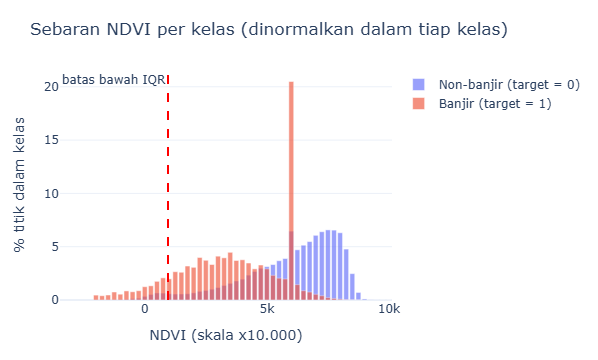

In [59]:

LEBAR_BIN = 250
sebaran_ndvi = (
    df_missing_handled
    .with_columns(((pl.col('NDVI') / LEBAR_BIN).floor() * LEBAR_BIN).alias('bin'))
    .group_by('target', 'bin').agg(pl.len().alias('n'))
    .with_columns((pl.col('n') / pl.col('n').sum().over('target') * 100).alias('persen'))
    .sort('target', 'bin')
)

fig3 = go.Figure()
for nilai, nama in [(0, 'Non-banjir (target = 0)'), (1, 'Banjir (target = 1)')]:
    sub = sebaran_ndvi.filter(pl.col('target') == nilai)
    fig3.add_bar(x=sub['bin'].to_list(), y=sub['persen'].to_list(), name=nama, opacity=0.65)
fig3.add_vline(x=batas['NDVI'][0], line_dash='dash', line_color='red',
               annotation_text='batas bawah IQR', annotation_position='top left')
fig3.update_layout(
    title='Sebaran NDVI per kelas (dinormalkan dalam tiap kelas)',
    xaxis_title='NDVI (skala x10.000)', yaxis_title='% titik dalam kelas', barmode='overlay',
)
tampilkan(fig3, 'qc_04_sebaran_ndvi')


### Simulasi winsorization 
Winsorization (`clip`) mengganti nilai di luar batas dengan nilai batas, tanpa menghapus baris. Berikut dampaknya pada `NDVI` jika dilakukan, untuk menilai apakah teknik ini layak dipakai.

In [29]:
simulasi = df_missing_handled.with_columns(
    pl.col('NDVI').clip(lower_bound=batas['NDVI'][0], upper_bound=batas['NDVI'][1]).alias('NDVI_wins')
)
n_berubah = simulasi.filter(pl.col('NDVI') != pl.col('NDVI_wins')).height
print(f'Nilai NDVI yang akan berubah: {n_berubah:,} ({n_berubah / len(simulasi):.2%})')

(simulasi.group_by('target')
    .agg(pl.col('NDVI').mean().round(1).alias('rata_NDVI_asli'),
         pl.col('NDVI_wins').mean().round(1).alias('rata_NDVI_winsorized'),
         pl.col('NDVI').min().alias('min_asli'),
         pl.col('NDVI_wins').min().alias('min_winsorized'))
    .sort('target'))

Nilai NDVI yang akan berubah: 30,024 (2.93%)


target,rata_NDVI_asli,rata_NDVI_winsorized,min_asli,min_winsorized
i64,f64,f64,f64,f64
0,6101.2,6117.5,-2000.0,951.25
1,3756.9,3875.2,-2000.0,951.25


- **Nilai asli dipertahankan dan tidak ada baris dibuang.** Semua nilai ekstrem masih berada dalam rentang fisik yang wajar (mis. hujan maksimum sekitar 107 mm/hari dan 220 mm per 3 hari), jadi bukan galat pengukuran.
- **Winsorization tidak diterapkan** pada kolom asli. Untuk `NDVI` dan `NDWI`, outlier jauh lebih sering muncul pada titik banjir, dan semua outlier `NDVI` berada di sisi rendah (kemungkinan area tergenang). Simulasi menunjukkan winsorization memotong nilai minimum `NDVI` dari -2000 menjadi sekitar 951 dan mengubah nilai pada sekitar 11% titik banjir, sehingga bagian ekor yang paling informatif hilang. Pengaruhnya pada rata-rata kecil (sekitar 3.757 menjadi 3.875 pada titik banjir), tetapi bentuk sebaran berubah.

In [60]:
df_outlier_handled = (
    df_missing_handled
    .with_columns(
        [((pl.col(k) < batas[k][0]) | (pl.col(k) > batas[k][1])).alias(f'outlier_{k}') for k in KOLOM_DINAMIS]
    )
    .with_columns(
        pl.sum_horizontal([pl.col(f'outlier_{k}').cast(pl.Int8) for k in KOLOM_DINAMIS]).alias('outlier_count')
    )
)

print(f'Baris: {len(df_outlier_handled):,} | kolom: {df_outlier_handled.width}')
print(f"Baris dengan minimal 1 penanda outlier: {df_outlier_handled.filter(pl.col('outlier_count') > 0).height:,}")

Baris: 1,025,801 | kolom: 22
Baris dengan minimal 1 penanda outlier: 100,071


## 5. Deduplikasi

Menentukan kolom kunci sebelum menghapus duplikasi. Satu titik grid (`date`, `lon`, `lat`) seharusnya hanya punya **satu pengamatan per tanggal**, sehingga ketiga kolom itu menjadi kunci gabungan.

In [61]:
KOLOM_KUNCI = ['date', 'lon', 'lat']

total_baris = len(df_outlier_handled)
baris_unik = df_outlier_handled.select(KOLOM_KUNCI).unique().height
duplikat_penuh = int(df_missing_handled.is_duplicated().sum())

print(f'Total baris: {total_baris:,}')
print(f'Baris unik berdasarkan {KOLOM_KUNCI}: {baris_unik:,}')
print(f'Duplikat kunci: {total_baris - baris_unik:,}')
print(f'Duplikat penuh (semua kolom): {duplikat_penuh:,}')

df_dedup = df_outlier_handled.unique(
    subset=KOLOM_KUNCI,
    keep='first',
    maintain_order=True,
)
print(f'Baris setelah deduplikasi: {len(df_dedup):,}')

Total baris: 1,025,801
Baris unik berdasarkan ['date', 'lon', 'lat']: 1,025,801
Duplikat kunci: 0
Duplikat penuh (semua kolom): 0
Baris setelah deduplikasi: 1,025,801


## 6. Validasi Data Dasar

Aturan validasi dibuat sesuai dataset ini dan dijalankan dengan **SQL di DuckDB**:

| Kelompok | Aturan | Dasar |
|---|---|---|
| Spasial | lon 118-123 dan lat -7 s.d. -1 | Kotak batas longgar Sulawesi bagian selatan |
| Temporal | tanggal 2003-2015 | Periode data menurut dokumentasi sumber |
| Label | `flooded`, `jrc_perm_water`, `target` hanya 0 atau 1 | Variabel biner |
| Konsistensi | `target = 1` jika dan hanya jika `flooded = 1` dan `jrc_perm_water = 0` | Terverifikasi di Milestone 1 |
| Hujan | tidak negatif, `precip_3d` ≥ `precip_1d`, `precip_1d` ≤ 500 mm | Akumulasi 3 hari tidak boleh lebih kecil dari 1 hari |
| Indeks | `NDVI` -2000 s.d. 10000, `NDWI` -1 s.d. 1 | Rentang valid indeks |
| Tutupan lahan | `landcover` 1-17 | Kelas tutupan lahan MODIS (asumsi, verifikasi di dokumentasi sumber) |
| Topografi | `elevation` 0-4000 m, `slope` 0-90°, `aspect` 0-360°, `upstream_area` > 0 | Batas fisik wajar |


In [62]:
connection.register('dataset_bersih', df_dedup)


def validasi_sql(tabel):
    """Menghitung pelanggaran setiap aturan validasi pada tabel yang terdaftar di DuckDB."""
    return connection.execute(f"""
        SELECT
            COUNT(*) AS total_baris,
            COUNT(*) FILTER (WHERE lon NOT BETWEEN 118 AND 123 OR lat NOT BETWEEN -7 AND -1) AS koordinat_di_luar_batas,
            COUNT(*) FILTER (WHERE date NOT BETWEEN DATE '2003-01-01' AND DATE '2015-12-31') AS tanggal_di_luar_periode,
            COUNT(*) FILTER (WHERE flooded NOT IN (0, 1) OR jrc_perm_water NOT IN (0, 1) OR target NOT IN (0, 1)) AS label_tidak_biner,
            COUNT(*) FILTER (WHERE (target = 1) <> (flooded = 1 AND jrc_perm_water = 0)) AS target_tidak_konsisten,
            COUNT(*) FILTER (WHERE precip_1d < 0 OR precip_3d < 0 OR precip_3d < precip_1d OR precip_1d > 500) AS hujan_tidak_valid,
            COUNT(*) FILTER (WHERE NDVI NOT BETWEEN -2000 AND 10000) AS ndvi_tidak_valid,
            COUNT(*) FILTER (WHERE NDWI NOT BETWEEN -1 AND 1) AS ndwi_tidak_valid,
            COUNT(*) FILTER (WHERE landcover NOT BETWEEN 1 AND 17) AS landcover_tidak_valid,
            COUNT(*) FILTER (WHERE elevation NOT BETWEEN 0 AND 4000 OR slope NOT BETWEEN 0 AND 90
                               OR aspect NOT BETWEEN 0 AND 360 OR upstream_area <= 0) AS topografi_tidak_valid,
            COUNT(*) FILTER (WHERE target = 1 AND elevation > 1000) AS flag_banjir_elevasi_tinggi
        FROM {tabel}
    """).pl()


validasi = validasi_sql('dataset_bersih')
validasi

total_baris,koordinat_di_luar_batas,tanggal_di_luar_periode,label_tidak_biner,target_tidak_konsisten,hujan_tidak_valid,ndvi_tidak_valid,ndwi_tidak_valid,landcover_tidak_valid,topografi_tidak_valid,flag_banjir_elevasi_tinggi
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
1025801,0,0,0,0,0,0,0,0,0,10


Baris yang melanggar aturan dibuang dengan ekspresi Polars yang setara dengan aturan SQL di atas. Pada dataset ini tidak ada pelanggaran, sehingga tidak ada baris yang terbuang.

In [64]:
ATURAN_KERAS = pl.all_horizontal(
    pl.col('lon').is_between(118, 123),
    pl.col('lat').is_between(-7, -1),
    pl.col('date').is_between(pl.date(2003, 1, 1), pl.date(2015, 12, 31)),
    pl.col('flooded').cast(pl.Float64).is_in([0.0, 1.0]),
    pl.col('jrc_perm_water').cast(pl.Float64).is_in([0.0, 1.0]),
    pl.col('target').cast(pl.Float64).is_in([0.0, 1.0]),
    (pl.col('target') == 1) == ((pl.col('flooded') == 1) & (pl.col('jrc_perm_water') == 0)),
    pl.col('precip_1d') >= 0,
    pl.col('precip_3d') >= pl.col('precip_1d'),
    pl.col('precip_1d') <= 500,
    pl.col('NDVI').is_between(-2000, 10000),
    pl.col('NDWI').is_between(-1, 1),
    pl.col('landcover').is_between(1, 17),
    pl.col('elevation').is_between(0, 4000),
    pl.col('slope').is_between(0, 90),
    pl.col('aspect').is_between(0, 360),
    pl.col('upstream_area') > 0,
)

df_valid = df_dedup.filter(ATURAN_KERAS)
print(f'Baris sebelum validasi: {len(df_dedup):,} | sesudah: {len(df_valid):,} | dibuang: {len(df_dedup) - len(df_valid):,}')

Baris sebelum validasi: 1,025,801 | sesudah: 1,025,801 | dibuang: 0


## 7. Simpan Data Bersih

Simpan hasil ke `data/processed/` agar dapat dipakai pada Milestone 3 tanpa mengulang proses cleaning. 
Sebelum disimpan dilakukan finalisasi tipe dan kolom turunan:

- `flooded`, `jrc_perm_water`, `landcover`, `target` → `Int8` (biner/kategorik, hemat memori). Kolom asli tetap ada.
- `NDVI_scaled` = `NDVI` / 10.000 agar skalanya sebanding dengan `NDWI`.
- `upstream_area_log`, `year`, dan penanda `suspect_high_elev_flood`.

In [65]:
df_bersih = df_valid.with_columns(
    pl.col('flooded').cast(pl.Int8),
    pl.col('jrc_perm_water').cast(pl.Int8),
    pl.col('landcover').cast(pl.Int8),
    pl.col('target').cast(pl.Int8),
    (pl.col('NDVI') / 10000).alias('NDVI_scaled'),
    pl.col('upstream_area').log1p().alias('upstream_area_log'),
    pl.col('date').dt.year().alias('year'),
    ((pl.col('target') == 1) & (pl.col('elevation') > 1000)).alias('suspect_high_elev_flood'),
)

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
df_bersih.write_parquet(OUTPUT_PATH)

print(f'Baris sebelum cleaning: {len(df):,}')
print(f'Baris sesudah cleaning: {len(df_bersih):,}')
print(f'Kolom: {df.width} -> {df_bersih.width}')
print(f'Data bersih tersimpan di: {OUTPUT_PATH}')
print(f'Ukuran file: {OUTPUT_PATH.stat().st_size / 1_000_000:.1f} MB')

Baris sebelum cleaning: 1,025,801
Baris sesudah cleaning: 1,025,801
Kolom: 16 -> 26
Data bersih tersimpan di: /home/jovyan/work/data/processed/dataset_bersih.parquet
Ukuran file: 36.4 MB


### Bukti sesudah cleaning
Profil `SUMMARIZE` dan validasi SQL dijalankan ulang pada data bersih, lalu dibandingkan dengan kondisi awal.

In [66]:
connection.register('dataset_final', df_bersih)

profil_sesudah = connection.execute('SUMMARIZE SELECT * FROM dataset_final').pl()
profil_sesudah.write_csv(str(TABLES_DIR / 'summarize_after.csv'))

validasi_sesudah = validasi_sql('dataset_final')
print('Pelanggaran aturan sesudah cleaning:')
validasi_sesudah

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Pelanggaran aturan sesudah cleaning:


total_baris,koordinat_di_luar_batas,tanggal_di_luar_periode,label_tidak_biner,target_tidak_konsisten,hujan_tidak_valid,ndvi_tidak_valid,ndwi_tidak_valid,landcover_tidak_valid,topografi_tidak_valid,flag_banjir_elevasi_tinggi
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
1025801,0,0,0,0,0,0,0,0,0,10


In [67]:
perbandingan = pl.DataFrame({
    'metrik': ['baris', 'kolom', 'total null', 'duplikat kunci (date, lon, lat)'],
    'sebelum': [
        len(df), df.width,
        int(df.null_count().sum_horizontal().sum()),
        len(df) - df.select(KOLOM_KUNCI).unique().height,
    ],
    'sesudah': [
        len(df_bersih), df_bersih.width,
        int(df_bersih.null_count().sum_horizontal().sum()),
        len(df_bersih) - df_bersih.select(KOLOM_KUNCI).unique().height,
    ],
})
perbandingan.write_csv(str(TABLES_DIR / 'before_after.csv'))
perbandingan

metrik,sebelum,sesudah
str,i64,i64
"""baris""",1025801,1025801
"""kolom""",16,26
"""total null""",0,0
"""duplikat kunci (date, lon, lat…",0,0


In [68]:
# Pemeriksaan otomatis: notebook berhenti dengan error jika masih ada aturan keras yang dilanggar
kolom_pelanggaran = [k for k in validasi_sesudah.columns if k not in ('total_baris', 'flag_banjir_elevasi_tinggi')]
assert sum(validasi_sesudah.select(kolom_pelanggaran).row(0)) == 0, 'Masih ada pelanggaran aturan validasi'
assert len(df_bersih) > 0
print('Semua aturan validasi terpenuhi pada data bersih.')

Semua aturan validasi terpenuhi pada data bersih.



## 8. Visualisasi Interaktif sesudah Cleaning


### 8.1 Efek transformasi log pada `upstream_area`

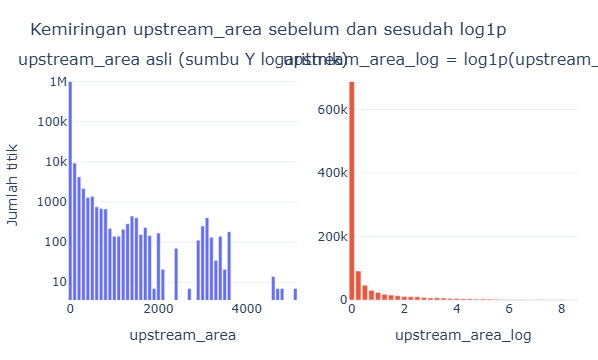

In [69]:

asli = (
    df_bersih.with_columns((pl.col('upstream_area') / 100).floor().mul(100).alias('bin'))
    .group_by('bin').agg(pl.len().alias('n')).sort('bin')
)
logaritma = (
    df_bersih.with_columns((pl.col('upstream_area_log') / 0.25).floor().mul(0.25).alias('bin'))
    .group_by('bin').agg(pl.len().alias('n')).sort('bin')
)

fig4 = make_subplots(rows=1, cols=2, subplot_titles=(
    'upstream_area asli (sumbu Y logaritmik)', 'upstream_area_log = log1p(upstream_area)'))
fig4.add_bar(x=asli['bin'].to_list(), y=asli['n'].to_list(), row=1, col=1)
fig4.add_bar(x=logaritma['bin'].to_list(), y=logaritma['n'].to_list(), row=1, col=2)
fig4.update_yaxes(type='log', row=1, col=1, title_text='Jumlah titik')
fig4.update_xaxes(title_text='upstream_area', row=1, col=1)
fig4.update_xaxes(title_text='upstream_area_log', row=1, col=2)
fig4.update_layout(title='Kemiringan upstream_area sebelum dan sesudah log1p', showlegend=False)
tampilkan(fig4, 'qc_05_upstream_area_log')


### 8.2 Skala `NDVI_scaled` dan `NDWI`

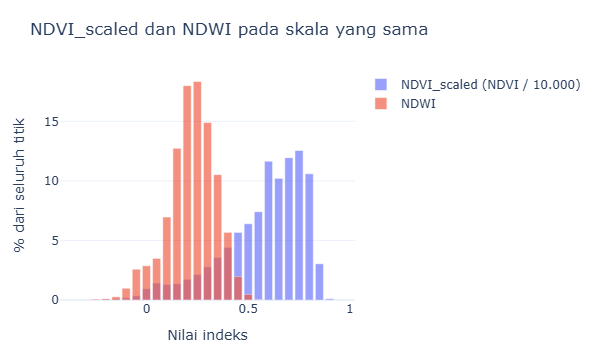

In [70]:

def hist_persen(kolom, lebar):
    return (
        df_bersih.with_columns((pl.col(kolom) / lebar).floor().mul(lebar).alias('bin'))
        .group_by('bin').agg(pl.len().alias('n'))
        .with_columns((pl.col('n') / len(df_bersih) * 100).alias('persen'))
        .sort('bin')
    )


ndvi_s = hist_persen('NDVI_scaled', 0.05)
ndwi_s = hist_persen('NDWI', 0.05)

fig6 = go.Figure()
fig6.add_bar(x=ndvi_s['bin'].to_list(), y=ndvi_s['persen'].to_list(), name='NDVI_scaled (NDVI / 10.000)', opacity=0.65)
fig6.add_bar(x=ndwi_s['bin'].to_list(), y=ndwi_s['persen'].to_list(), name='NDWI', opacity=0.65)
fig6.update_layout(title='NDVI_scaled dan NDWI pada skala yang sama', barmode='overlay',
                   xaxis_title='Nilai indeks', yaxis_title='% dari seluruh titik')
tampilkan(fig6, 'qc_06_skala_ndvi_ndwi')


setelah dibagi 10.000, `NDVI_scaled` berada pada rentang -0,2 sampai 1,0 sehingga sebanding dengan `NDWI` (sekitar -0,39 sampai 0,60). Penyeragaman skala berhasil.

## Ringkasan 

**Dimensi kualitas data yang paling bermasalah:** bukan missing values atau duplikat (keduanya nol), melainkan:
1. Skala `NDVI` (-2000 s.d. 10000) yang berbeda dari `NDWI` (-1 s.d. 1).
2. Kolom biner dan kategorik (`flooded`, `jrc_perm_water`, `landcover`) bertipe desimal.
3. Variabel topografi (`elevation`, `slope`, `upstream_area`) sangat miring ke kanan, sehingga IQR menandai sekitar 10-18% baris sebagai outlier padahal nilainya valid.
4. Kelas `target` tidak seimbang (sekitar 4,5% banjir).
5. 10 titik banjir pada elevasi di atas 1000 m yang ditandai untuk diperiksa.

**Strategi missing values:** tidak ada null maupun NaN. Kebijakan tetap dijalankan di pipeline: baris dengan kunci analisis kosong dibuang, kolom numerik diisi median, `landcover` diisi modus.

**Strategi outlier:** IQR dipakai untuk mendeteksi, tetapi nilai tidak dibuang dan tidak di-winsorize karena masih wajar secara fisik dan membawa sinyal banjir (proporsi outlier `NDVI` dan `NDWI` jauh lebih tinggi pada titik banjir). Outlier hanya ditandai lewat kolom `outlier_*` dan `outlier_count`. `upstream_area_log` dibuat untuk menangani kemiringan distribusi.

**Jumlah baris yang berubah:** 1.025.801 sebelum dan sesudah. Tidak ada baris dibuang karena data sudah bersih sejak dari sumbernya (terlihat dari nama file). Kolom bertambah dari 16 menjadi 26 (kolom turunan dan penanda).

**Aturan validasi yang diterapkan:** koordinat dan tanggal dalam batas, label biner, konsistensi `target`, hujan tidak negatif dan akumulasi 3 hari ≥ 1 hari, rentang `NDVI`/`NDWI`, `landcover` 1-17, serta batas fisik `elevation`, `slope`, `aspect`, dan `upstream_area`. Seluruhnya terpenuhi (0 pelanggaran) dan diperiksa otomatis dengan `assert`.

**Keluaran:** `data/processed/dataset_bersih.parquet` (tidak di-commit) dan tabel di `output/tables/` (`summarize_before.csv`, `summarize_after.csv`, `outlier_iqr.csv`, `before_after.csv`).